# OFDM Simulation

This notebook simulates an OFDM link. It compares an ideal channel, additive white Gaussian noise (AWGN), carrier frequency offset, and their combined effect. The evaluation compares recovered bits with the transmitted bits and records missed symbols.

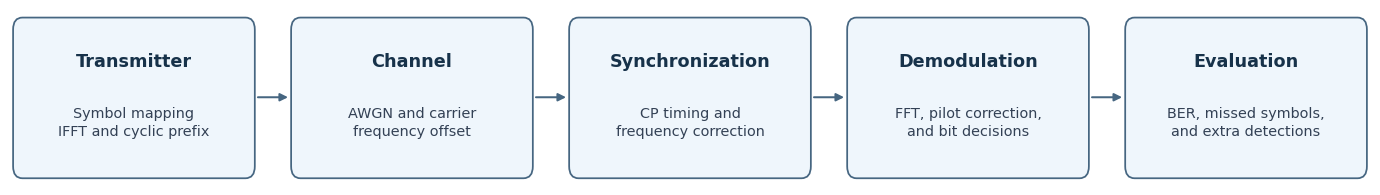

### Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import mlab
from matplotlib.patches import Rectangle
from scipy.signal import correlate, find_peaks
from IPython.display import Markdown, display

## OFDM and Modulation Parameters

The table lists the configured values and the quantities derived from them. The nominal data rate includes cyclic-prefix overhead and uses only data subcarriers.

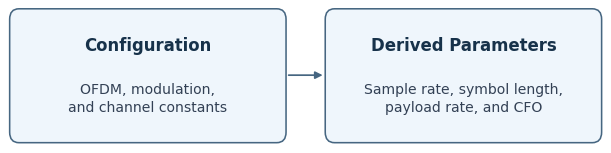

### OFDM, Modulation, and Channel Constants

In [31]:
# Simulation
RANDOM_SEED = 42

# OFDM
FFT_LEN = 128
CP_DIVISOR = 4
SUBCARRIER_SPACING_HZ = 15e3
NUM_PILOT_SUBCARRIERS = 6
NUM_DATA_SUBCARRIERS = 72
PILOT_VALUE = -1 + 1j
NUM_GENERATED_POINTS = 32_768

# Modulation
BITS_PER_SYMBOL = 2

# Channel
SNR_DB = 5
CHANNEL_CFO_CYCLES_PER_SAMPLE = 500e-6

# Synchronization
BURST_ENERGY_FRACTION = 0.5
TIMING_ACQUISITION_SYMBOLS = 16
CP_LOCK_THRESHOLD = 0.15
CP_PEAK_THRESHOLD = 0.4

### Calculate Derived Parameters

In [32]:
cp_len = FFT_LEN // CP_DIVISOR
num_null_subcarriers = FFT_LEN - NUM_DATA_SUBCARRIERS - NUM_PILOT_SUBCARRIERS
sample_rate = int(FFT_LEN * SUBCARRIER_SPACING_HZ)
symbol_samples = FFT_LEN + cp_len
payload_bits_per_symbol = NUM_DATA_SUBCARRIERS * BITS_PER_SYMBOL
payload_rate_mibits = payload_bits_per_symbol * sample_rate / symbol_samples / 1024**2
subcarrier_spacing_khz = SUBCARRIER_SPACING_HZ / 1e3
sample_rate_mhz = sample_rate / 1e6
symbol_duration_us = symbol_samples / sample_rate * 1e6
channel_cfo_hz = CHANNEL_CFO_CYCLES_PER_SAMPLE * sample_rate

In [33]:
parameters = [
    ("Simulation", "Random seed", f"{RANDOM_SEED}", "-"),
    ("OFDM", "FFT size", f"{FFT_LEN:,}", "bins"),
    ("OFDM", "Subcarrier spacing", f"{subcarrier_spacing_khz:g}", "kHz"),
    ("OFDM", "Sample rate", f"{sample_rate_mhz:g}", "MHz"),
    ("OFDM", "Cyclic prefix fraction", f"1/{CP_DIVISOR}", "of FFT length"),
    ("OFDM", "Cyclic prefix length", f"{cp_len:,}", "samples"),
    ("OFDM", "OFDM symbol length", f"{symbol_samples:,}", "samples"),
    ("OFDM", "OFDM symbol duration", f"{symbol_duration_us:.3f}", "µs"),
    ("OFDM", "Data subcarriers", f"{NUM_DATA_SUBCARRIERS:,}", "bins"),
    ("OFDM", "Pilot subcarriers", f"{NUM_PILOT_SUBCARRIERS:,}", "bins"),
    ("OFDM", "Null subcarriers (including DC)", f"{num_null_subcarriers:,}", "bins"),
    ("OFDM", "Pilot value", f"{PILOT_VALUE:g}", "complex amplitude"),
    ("Modulation", "Bits per constellation point", f"{BITS_PER_SYMBOL:,}", "bits"),
    ("Modulation", "Generated constellation points", f"{NUM_GENERATED_POINTS:,}", "points"),
    ("Modulation", "Payload bits per OFDM symbol", f"{payload_bits_per_symbol:,}", "bits"),
    ("Modulation", "Nominal data rate", f"{payload_rate_mibits:.3f}", "Mibit/s"),
    ("Channel", "Signal-to-noise ratio", f"{SNR_DB:g}", "dB"),
    ("Channel", "Normalized carrier frequency offset", f"{CHANNEL_CFO_CYCLES_PER_SAMPLE:g}", "cycles/sample"),
    ("Channel", "Carrier frequency offset", f"{channel_cfo_hz:g}", "Hz"),
    ("Synchronization", "Burst energy threshold fraction", f"{BURST_ENERGY_FRACTION:g}", "fraction"),
    ("Synchronization", "Maximum symbols for timing acquisition", f"{TIMING_ACQUISITION_SYMBOLS}", "symbols"),
    ("Synchronization", "Minimum mean CP score for lock", f"{CP_LOCK_THRESHOLD:g}", "ratio"),
    ("Synchronization", "Local CP peak threshold", f"{CP_PEAK_THRESHOLD:g}", "ratio"),
]
table = [
    "| Group | Parameter | Value | Unit |",
    "| --- | --- | ---: | --- |",
]
table.extend(f"| {group} | {parameter} | {value} | {unit} |"
             for group, parameter, value, unit in parameters)
display(Markdown("\n".join(table)))

| Group | Parameter | Value | Unit |
| --- | --- | ---: | --- |
| Simulation | Random seed | 42 | - |
| OFDM | FFT size | 128 | bins |
| OFDM | Subcarrier spacing | 15 | kHz |
| OFDM | Sample rate | 1.92 | MHz |
| OFDM | Cyclic prefix fraction | 1/4 | of FFT length |
| OFDM | Cyclic prefix length | 32 | samples |
| OFDM | OFDM symbol length | 160 | samples |
| OFDM | OFDM symbol duration | 83.333 | µs |
| OFDM | Data subcarriers | 72 | bins |
| OFDM | Pilot subcarriers | 6 | bins |
| OFDM | Null subcarriers (including DC) | 50 | bins |
| OFDM | Pilot value | -1+1j | complex amplitude |
| Modulation | Bits per constellation point | 2 | bits |
| Modulation | Generated constellation points | 32,768 | points |
| Modulation | Payload bits per OFDM symbol | 144 | bits |
| Modulation | Nominal data rate | 1.648 | Mibit/s |
| Channel | Signal-to-noise ratio | 5 | dB |
| Channel | Normalized carrier frequency offset | 0.0005 | cycles/sample |
| Channel | Carrier frequency offset | 960 | Hz |
| Synchronization | Burst energy threshold fraction | 0.5 | fraction |
| Synchronization | Maximum symbols for timing acquisition | 16 | symbols |
| Synchronization | Minimum mean CP score for lock | 0.15 | ratio |
| Synchronization | Local CP peak threshold | 0.4 | ratio |

## Transmitter

Subcarrier allocation is 72 data, 6 pilot, and 50 null. Nulls include DC and the guard bands.

Map constellation symbols and pilots to their assigned bins, apply the IFFT, and prepend the cyclic prefix. Concatenate and normalize the time-domain symbols to form `ofdm_signal`.

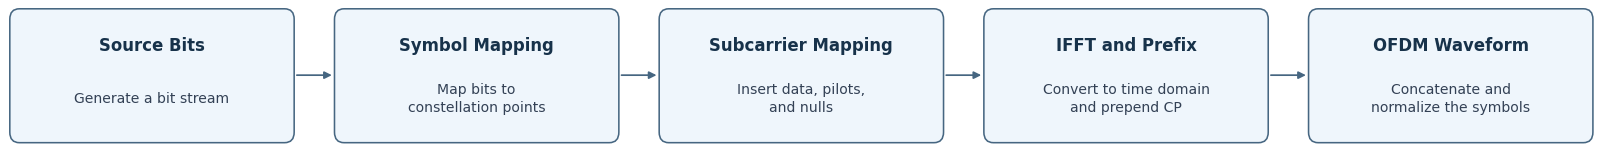

### Allocate Data, Pilot, and Null Subcarriers

In [34]:
# 0 = null, 1 = pilot, 2 = data
subcarrier_map = np.full(FFT_LEN, 2, dtype=int)
dc_index = FFT_LEN // 2
subcarrier_map[dc_index] = 0
num_guards = num_null_subcarriers - 1
guard_right = num_guards // 2
guard_left = num_guards - guard_right
subcarrier_map[:guard_left] = 0
subcarrier_map[FFT_LEN - guard_right:] = 0


# Space pilot indices evenly across the active band.
pilot_positions = np.linspace(
    0, FFT_LEN - num_null_subcarriers, NUM_PILOT_SUBCARRIERS + 2, dtype=int
)
pilot_indices = pilot_positions[1:-1] + num_null_subcarriers // 2
subcarrier_map[pilot_indices] = 1

pilot_mask = np.where(subcarrier_map == 1)[0]
data_mask = np.where(subcarrier_map == 2)[0]
null_mask = np.where(subcarrier_map == 0)[0]
subcarrier_indices = np.arange(FFT_LEN) - dc_index

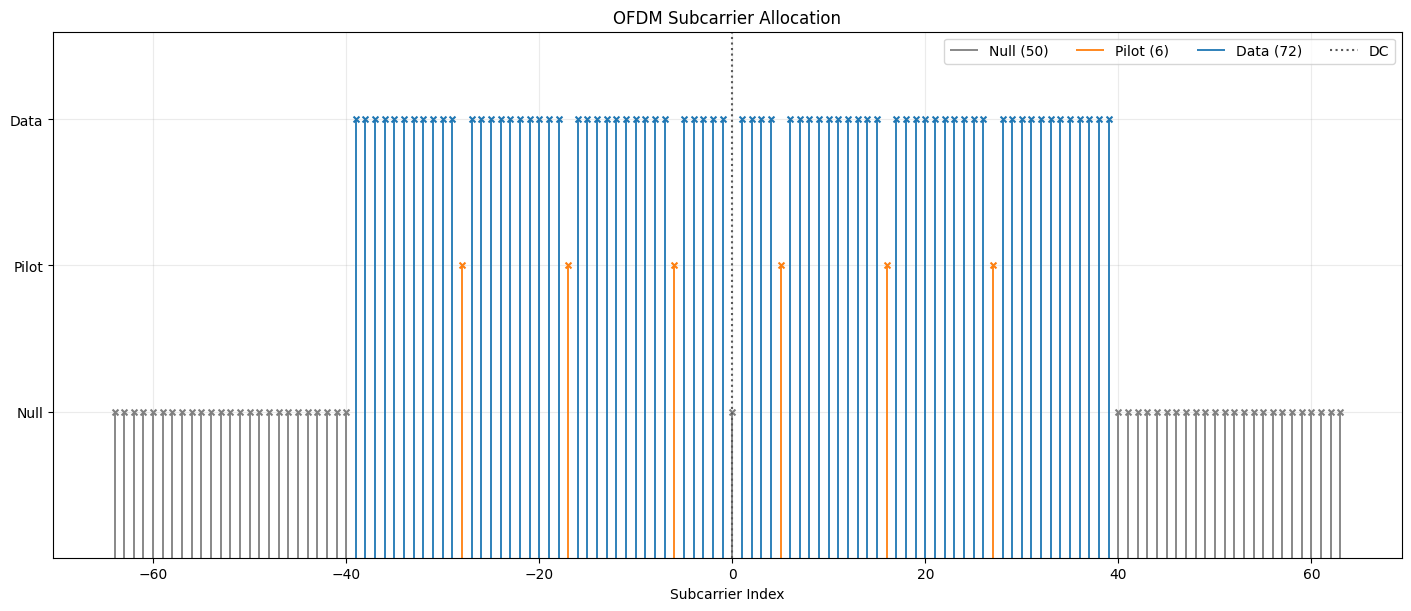

In [35]:
fig, ax = plt.subplots(figsize=(14, 6), layout="constrained")
for mask, level, label, color in (
    (null_mask, 1, "Null", "tab:gray"),
    (pilot_mask, 2, "Pilot", "tab:orange"),
    (data_mask, 3, "Data", "tab:blue"),
):
    indices = subcarrier_indices[mask]
    ax.vlines(indices, 0, level, color=color, linewidth=1.3,
              label=f"{label} ({len(mask)})")
    ax.scatter(indices, np.full(len(mask), level), marker="x", s=18, color=color)
ax.axvline(0, color="0.35", linestyle=":", label="DC")
ax.set(title="OFDM Subcarrier Allocation", xlabel="Subcarrier Index",
       yticks=[1, 2, 3], yticklabels=["Null", "Pilot", "Data"], ylim=(0, 3.6))
ax.grid(alpha=0.25)
ax.legend(loc="upper right", ncols=4)
plt.show()

### Generate Bits and Map Constellation Points

In [36]:
rng = np.random.RandomState(RANDOM_SEED)
transmit_bits = rng.randint(0, 2, NUM_GENERATED_POINTS * BITS_PER_SYMBOL)
in_phase = 2 * transmit_bits[::2] - 1
quadrature = 2 * transmit_bits[1::2] - 1
mapped_points = in_phase + 1j * quadrature

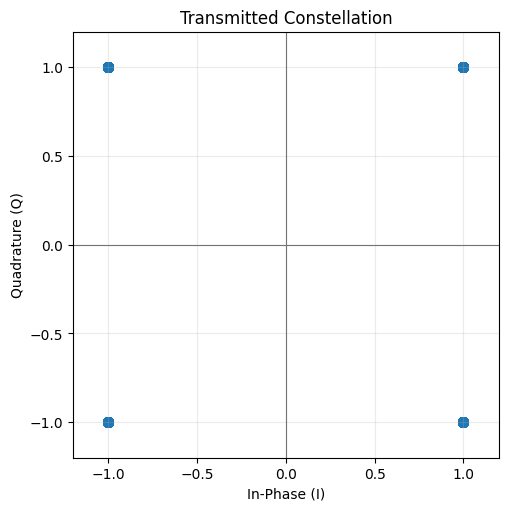

In [37]:
fig, ax = plt.subplots(figsize=(5, 5), layout="constrained")
ax.scatter(mapped_points.real, mapped_points.imag, s=45, color="tab:blue")
ax.axhline(0, color="0.45", linewidth=0.8)
ax.axvline(0, color="0.45", linewidth=0.8)
ax.set(title="Transmitted Constellation", xlabel="In-Phase (I)",
       ylabel="Quadrature (Q)", xlim=(-1.2, 1.2), ylim=(-1.2, 1.2))
ax.set_aspect("equal")
ax.grid(alpha=0.25)
plt.show()

### Build the OFDM Packet

In [38]:
points_per_ofdm_symbol = len(data_mask)
num_symbols = len(mapped_points) // points_per_ofdm_symbol
used_points = mapped_points[:num_symbols * points_per_ofdm_symbol]
points_by_symbol = used_points.reshape(num_symbols, -1)

ofdm_symbols = []
for symbol_points in points_by_symbol:
    frequency_bins = np.zeros(FFT_LEN, dtype=complex)
    frequency_bins[data_mask] = symbol_points
    frequency_bins[pilot_mask] = PILOT_VALUE

    time_samples = np.fft.ifft(np.fft.fftshift(frequency_bins))
    cyclic_prefix = time_samples[-cp_len:]
    samples_with_cp = np.concatenate([cyclic_prefix, time_samples])
    ofdm_symbols.append(samples_with_cp)

ofdm_signal = np.concatenate(ofdm_symbols)
ofdm_signal = ofdm_signal / np.max(abs(ofdm_signal))

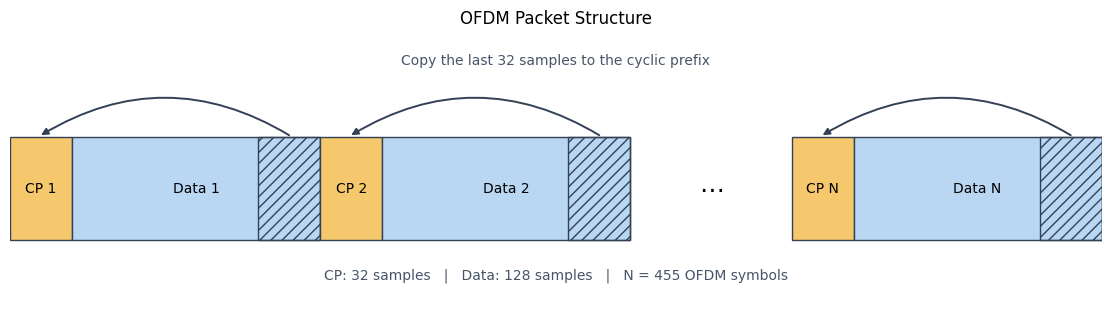

In [39]:
fig, ax = plt.subplots(figsize=(11, 3), layout="constrained")
ax.set_title("OFDM Packet Structure", pad=12)
symbol_labels = [1, 2, None, "N"] if num_symbols > 3 else range(1, num_symbols + 1)
x = 0
for label in symbol_labels:
    if label is None:
        gap = FFT_LEN * 0.65
        ax.text(x + gap / 2, 0.5, r"$\cdots$", ha="center", va="center", fontsize=18)
        x += gap
        continue

    symbol_start = x
    for width, field, color in (
        (cp_len, "CP", "#F6C86E"),
        (FFT_LEN, "Data", "#B9D7F2"),
    ):
        ax.add_patch(Rectangle((x, 0), width, 1, facecolor=color, edgecolor="#334155"))
        ax.text(x + width / 2, 0.5, f"{field} {label}", ha="center", va="center")
        x += width

    tail_start = x - cp_len
    ax.add_patch(Rectangle((tail_start, 0), cp_len, 1, facecolor="none",
                           edgecolor="#334155", hatch="///"))
    ax.annotate("", xy=(symbol_start + cp_len / 2, 1.02),
                xytext=(tail_start + cp_len / 2, 1.02),
                arrowprops=dict(arrowstyle="-|>", connectionstyle="arc3,rad=0.30",
                                color="#334155", linewidth=1.4, shrinkA=0, shrinkB=0))

ax.text(x / 2, 1.75, f"Copy the last {cp_len} samples to the cyclic prefix",
        ha="center", va="center", color="#475569")
ax.text(x / 2, -0.35,
        f"CP: {cp_len} samples   |   Data: {FFT_LEN} samples   |   N = {num_symbols} OFDM symbols",
        ha="center", va="center", color="#475569")
ax.set(xlim=(0, x), ylim=(-0.6, 1.95))
ax.axis("off")
plt.show()

### Calculate the Transmit Spectrum and Spectrogram

In [40]:
NFFT = 1024


def calculate_psd(signal, nfft):
    power, frequencies = mlab.psd(signal, NFFT=nfft, Fs=sample_rate)
    return frequencies, 10 * np.log10(power)


def calculate_spectrogram(signal, noverlap=128):
    power, frequencies, times = mlab.specgram(
        signal, NFFT=NFFT, Fs=sample_rate, noverlap=noverlap
    )
    power_db = 10 * np.log10(np.maximum(power, np.finfo(power.dtype).tiny))
    return frequencies, times, power_db.T


transmitted_psd = calculate_psd(ofdm_signal, NFFT)
transmitted_spectrogram = calculate_spectrogram(ofdm_signal)
transmitted_peak_db = transmitted_spectrogram[2].max()

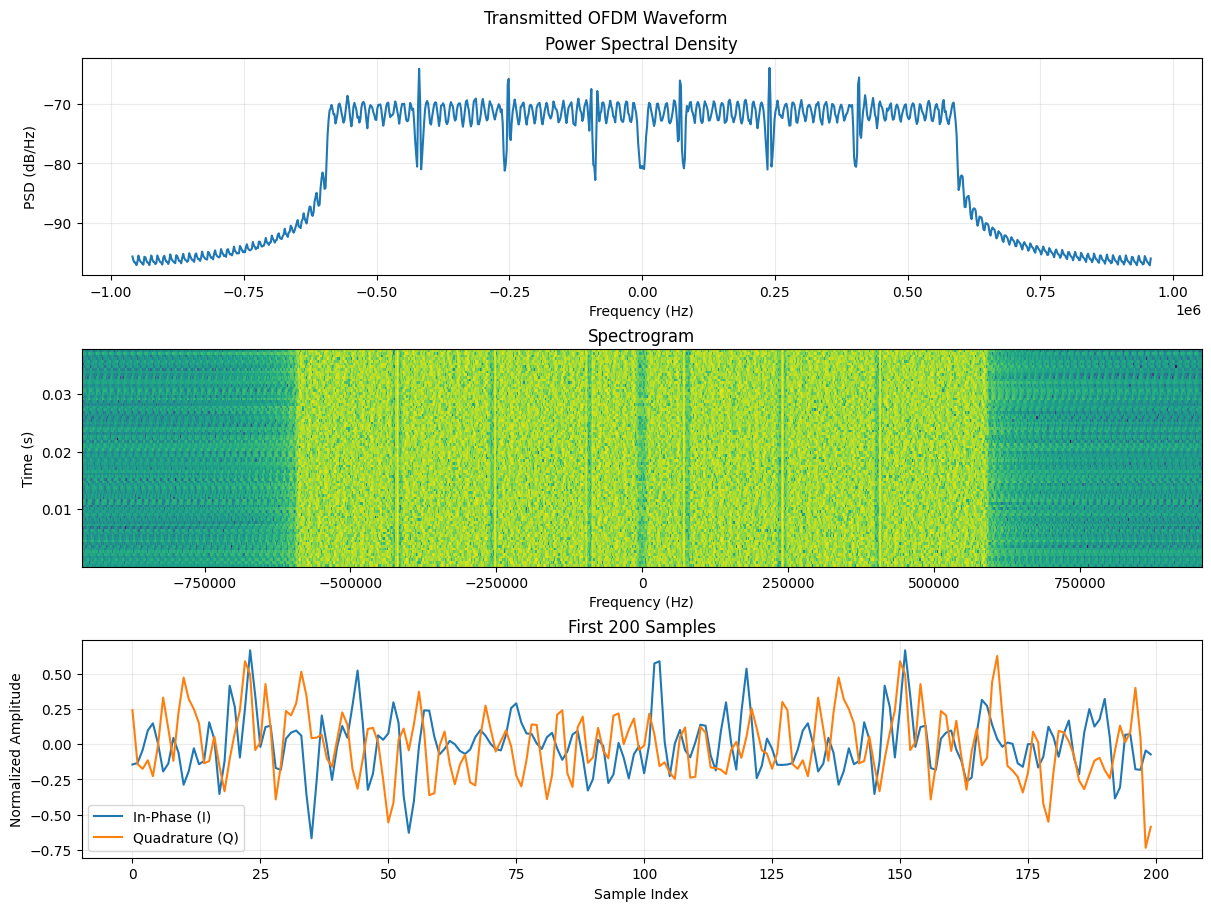

In [41]:
def plot_psd(ax, spectrum, title):
    frequencies, power_db = spectrum
    ax.plot(frequencies, power_db)
    ax.set(title=title, xlabel="Frequency (Hz)", ylabel="PSD (dB/Hz)")
    ax.grid(alpha=0.25)


def plot_spectrogram(ax, spectrogram, title, peak_db):
    frequencies, times, power_db = spectrogram
    ax.pcolormesh(frequencies, times, power_db, shading="auto", cmap="viridis",
                  vmin=peak_db - 80, vmax=peak_db)
    ax.set(title=title, xlabel="Frequency (Hz)", ylabel="Time (s)")


fig, axes = plt.subplots(3, 1, figsize=(12, 9), layout="constrained")
fig.suptitle("Transmitted OFDM Waveform")
plot_psd(axes[0], transmitted_psd, "Power Spectral Density")
plot_spectrogram(axes[1], transmitted_spectrogram, "Spectrogram", transmitted_peak_db)

axes[2].plot(ofdm_signal[:200].real, label="In-Phase (I)")
axes[2].plot(ofdm_signal[:200].imag, label="Quadrature (Q)")
axes[2].set(title="First 200 Samples", xlabel="Sample Index", ylabel="Normalized Amplitude")
axes[2].grid(alpha=0.25)
axes[2].legend()
plt.show()

### Filter the Transmit Waveform

In [42]:
NUM_FILTER_TAPS = 101
cutoff_hz = sample_rate / 2 * 0.8
tap_offsets = np.arange(NUM_FILTER_TAPS) - (NUM_FILTER_TAPS - 1) // 2
sinc_response = np.sinc(2 * cutoff_hz / sample_rate * tap_offsets)
filter_coefficients = sinc_response * np.hamming(NUM_FILTER_TAPS)

filtered_i = np.convolve(ofdm_signal.real, filter_coefficients, mode="same")
filtered_q = np.convolve(ofdm_signal.imag, filter_coefficients, mode="same")
filtered_ofdm_signal = filtered_i.astype(np.float32) + 1j * filtered_q.astype(np.float32)

filtered_psd = calculate_psd(filtered_ofdm_signal, NFFT)
filtered_spectrogram = calculate_spectrogram(filtered_ofdm_signal)
filtered_peak_db = filtered_spectrogram[2].max()

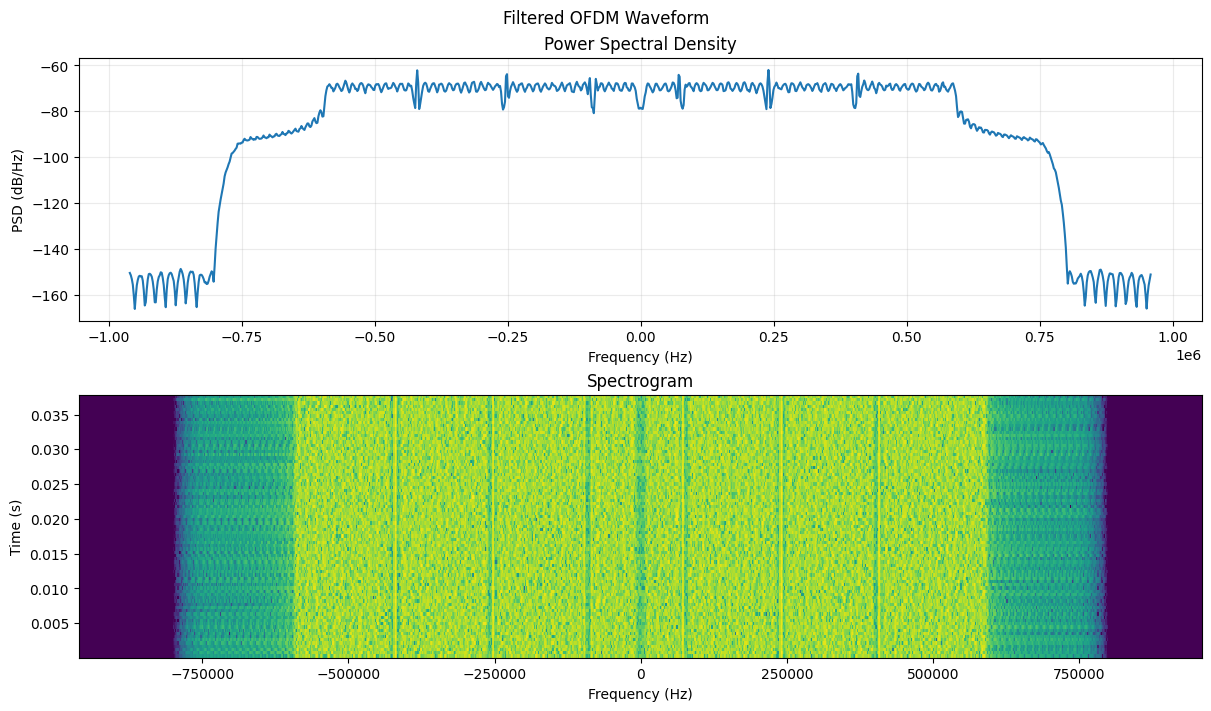

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), layout="constrained")
fig.suptitle("Filtered OFDM Waveform")
plot_psd(axes[0], filtered_psd, "Power Spectral Density")
plot_spectrogram(axes[1], filtered_spectrogram, "Spectrogram", filtered_peak_db)
plt.show()

## Channel Model

The channel input is `ofdm_signal` with zero padding before and after the packet. The filtered waveform `filtered_ofdm_signal` is computed separately.

The four cases are ideal, complex additive white Gaussian noise (AWGN), CFO, and AWGN with CFO.

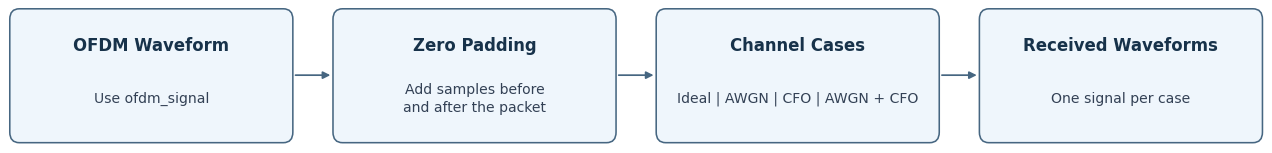

### Pad the Packet and Add Noise

In [44]:

leading_padding_samples = int(0.5 * len(ofdm_signal))
trailing_padding_samples = int(leading_padding_samples * 0.5)
received_sample_count = len(ofdm_signal) + leading_padding_samples + trailing_padding_samples
rx_signal = np.zeros(received_sample_count, dtype=np.complex64)
rx_signal[leading_padding_samples:-trailing_padding_samples] = ofdm_signal

signal_power = np.mean(np.abs(ofdm_signal)**2)
noise_power = signal_power / (10 ** (SNR_DB / 10))
noise = np.sqrt(noise_power/2) * (rng.randn(len(rx_signal)) + 1j*rng.randn(len(rx_signal)))
noise_rx_signal = rx_signal + noise

packet_slice = slice(leading_padding_samples, -trailing_padding_samples)
ideal_psd = calculate_psd(ofdm_signal, 256)
noise_psd = calculate_psd(noise_rx_signal[packet_slice], 256)
ideal_spectrogram = calculate_spectrogram(rx_signal)
noise_spectrogram = calculate_spectrogram(noise_rx_signal)
channel_peak_db = max(ideal_spectrogram[2].max(), noise_spectrogram[2].max())

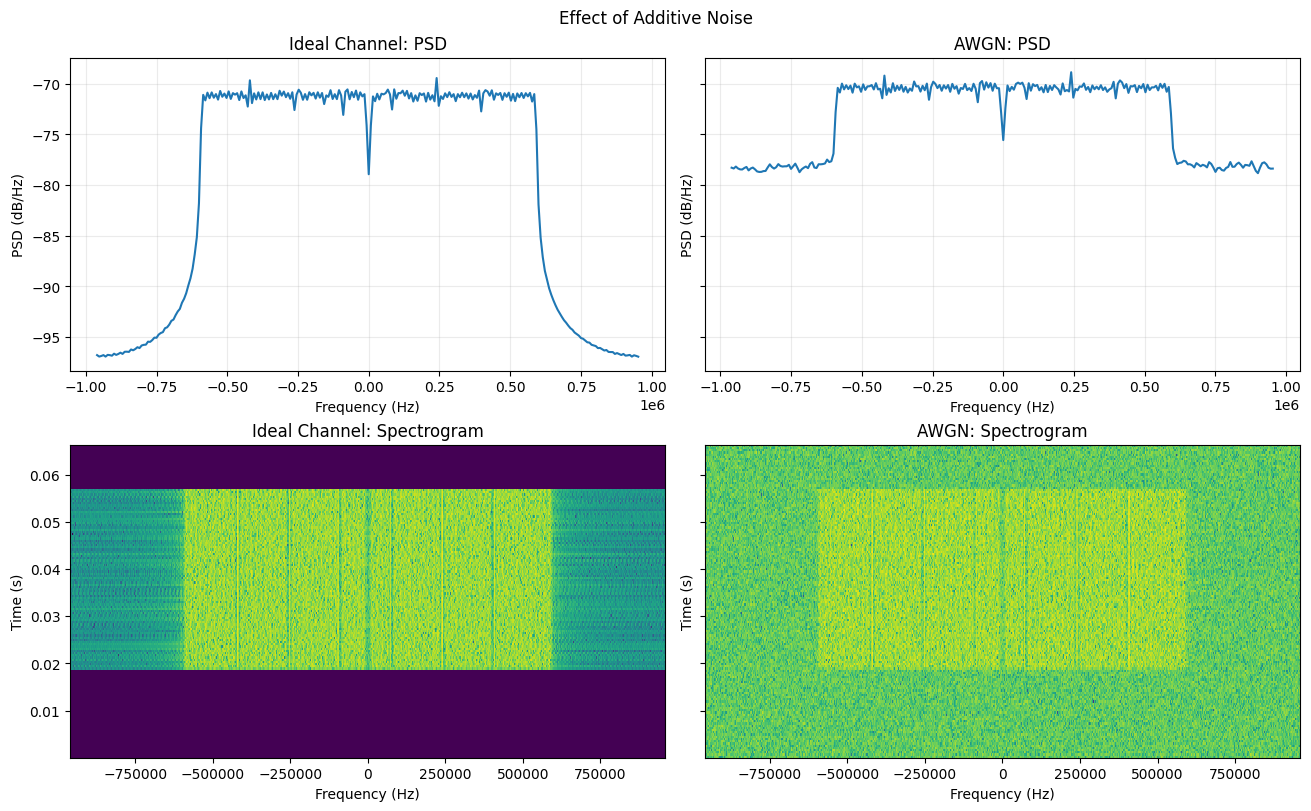

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharey="row", layout="constrained")
fig.suptitle("Effect of Additive Noise")
plot_psd(axes[0, 0], ideal_psd, "Ideal Channel: PSD")
plot_psd(axes[0, 1], noise_psd, "AWGN: PSD")
plot_spectrogram(axes[1, 0], ideal_spectrogram, "Ideal Channel: Spectrogram", channel_peak_db)
plot_spectrogram(axes[1, 1], noise_spectrogram, "AWGN: Spectrogram", channel_peak_db)
plt.show()

### Apply the Carrier Frequency Offset

In [46]:
sample_indices = np.arange(len(rx_signal))
channel_rotation = np.exp(1j * 2 * np.pi * CHANNEL_CFO_CYCLES_PER_SAMPLE * sample_indices)

channel_signals = {
    "ideal": rx_signal,
    "awgn": noise_rx_signal,
    "cfo": rx_signal * channel_rotation,
    "awgn_cfo": noise_rx_signal * channel_rotation,
}
channel_titles = {
    "ideal": "Ideal Channel",
    "awgn": "AWGN",
    "cfo": "Frequency Offset",
    "awgn_cfo": "AWGN and Frequency Offset",
}

received_psds = {
    "ideal": calculate_psd(channel_signals["ideal"][packet_slice], 256),
    "awgn": noise_psd,
    "cfo": calculate_psd(channel_signals["cfo"][packet_slice], 256),
    "awgn_cfo": calculate_psd(channel_signals["awgn_cfo"][packet_slice], 256),
}

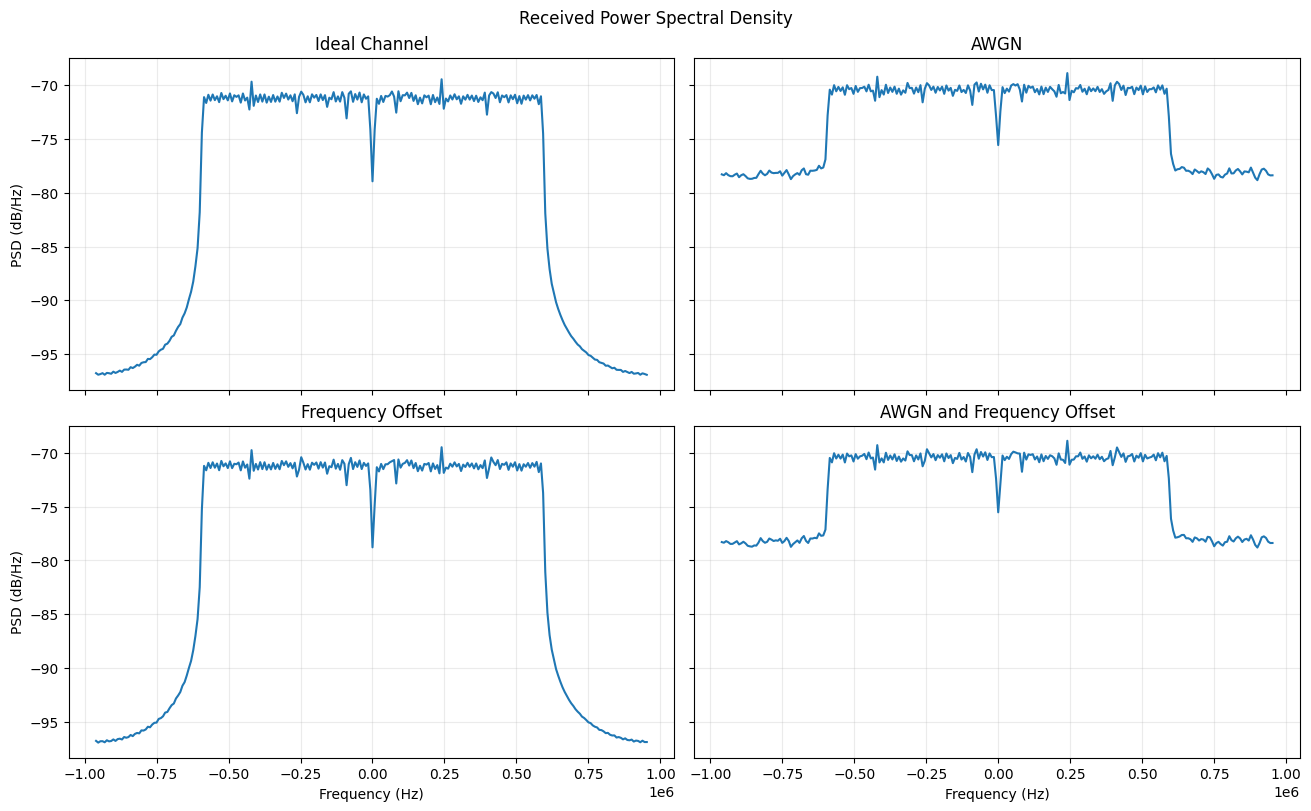

In [47]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Received Power Spectral Density")
for ax, (case, title) in zip(axes.flat, channel_titles.items()):
    plot_psd(ax, received_psds[case], title)
    ax.label_outer()
plt.show()

## Receiver and Synchronization

Locate the burst by energy. Score candidate symbol starts using cyclic-prefix correlation across several symbols, then extract symbols on the acquired grid. Estimate CFO from the cyclic-prefix correlation phase.

Remove the cyclic prefix and apply the FFT. Use the pilots to correct the residual common phase, then extract the data subcarriers.

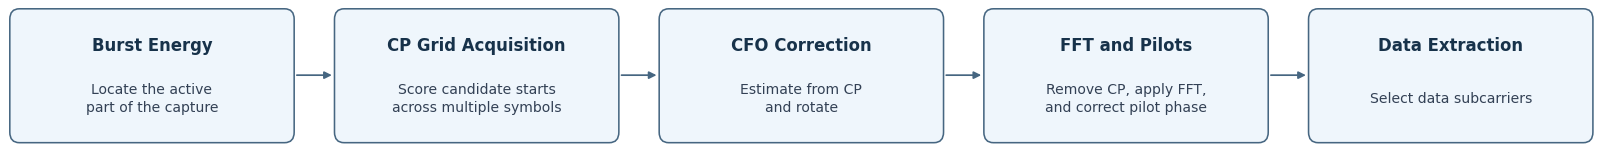

### Calculate Cyclic-Prefix Correlation

In [48]:
def calculate_cp_metric(signal):
    metric_values = []
    for start in range(len(signal) - symbol_samples + 1):
        prefix = signal[start : start + cp_len]
        tail_start = start + FFT_LEN
        tail = signal[tail_start : tail_start + cp_len]

        cp_correlation = correlate(prefix, tail, mode="valid")[0]
        prefix_energy = np.linalg.norm(prefix)**2
        tail_energy = np.linalg.norm(tail)**2
        energy_product = prefix_energy * tail_energy

        metric = np.abs(cp_correlation)**2 / energy_product if energy_product > 0 else 0
        metric_values.append(metric)
    return np.array(metric_values)


cp_metrics = {case: calculate_cp_metric(signal) for case, signal in channel_signals.items()}

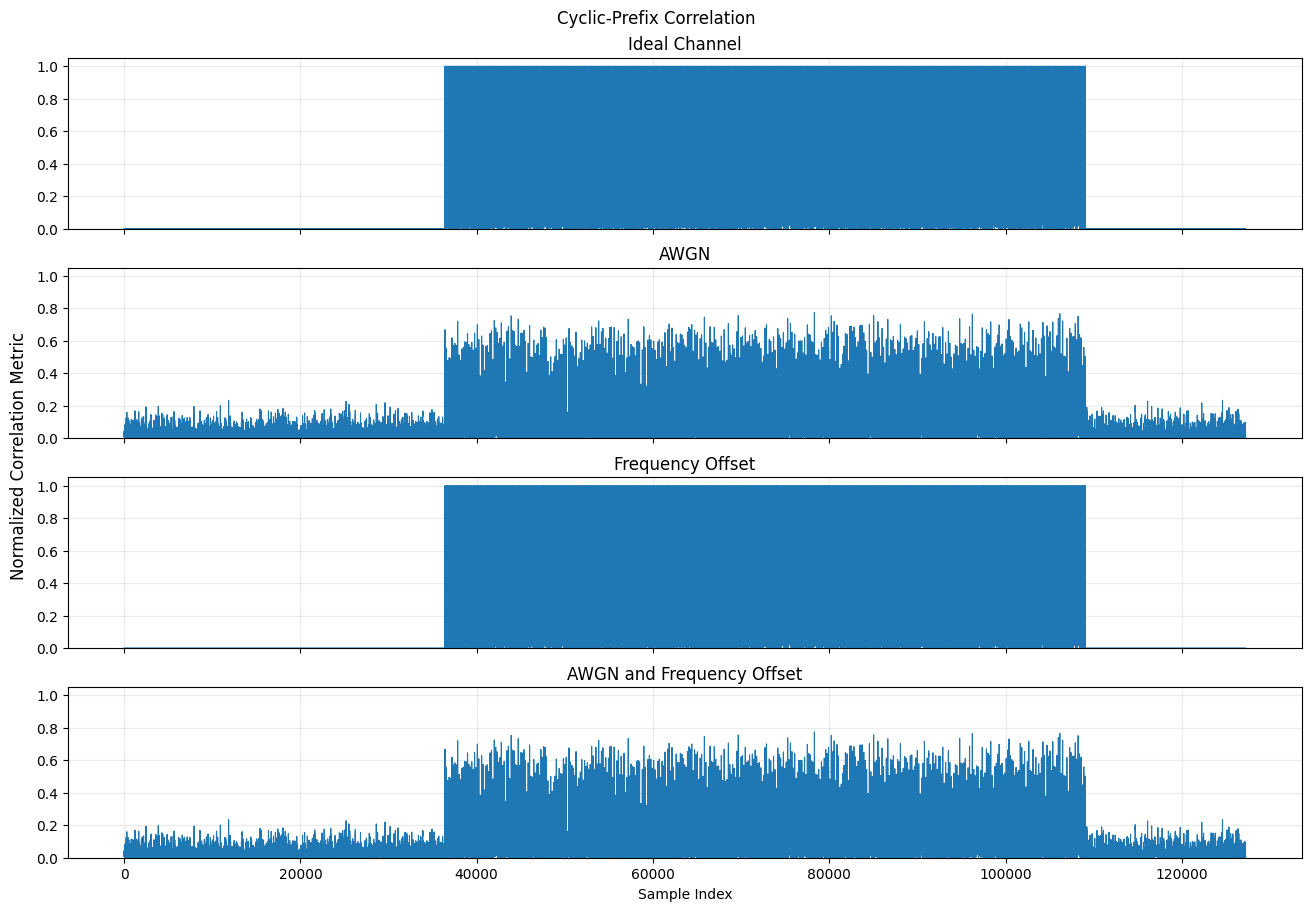

In [49]:
fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Cyclic-Prefix Correlation")
for ax, (case, title) in zip(axes, channel_titles.items()):
    ax.plot(cp_metrics[case], linewidth=0.8)
    ax.set(title=title, ylim=(0, 1.05))
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Sample Index")
fig.supylabel("Normalized Correlation Metric")
plt.show()

### Find Local CP Peaks

In [50]:
min_peak_distance = symbol_samples - 2
local_cp_peaks = {}
for case, metric in cp_metrics.items():
    peaks, _ = find_peaks(metric, height=CP_PEAK_THRESHOLD, distance=min_peak_distance)
    local_cp_peaks[case] = peaks

### Acquire the OFDM Symbol Grid

In [51]:
def calculate_burst_energy(signal):
    # Average power over one symbol. The capture has quiet margins at both ends.
    energy_window = np.full(symbol_samples, 1 / symbol_samples)
    window_power = np.convolve(np.abs(signal)**2, energy_window, mode="valid")
    edge_windows = np.concatenate((window_power[:cp_len], window_power[-cp_len:]))
    noise_floor = np.median(edge_windows)
    peak_power = window_power.max()
    threshold = noise_floor + BURST_ENERGY_FRACTION * (peak_power - noise_floor)
    if peak_power <= noise_floor:
        threshold = None
    return window_power, threshold


def find_burst_bounds(window_power, threshold):
    if threshold is None:
        return None
    active_windows = np.flatnonzero(window_power >= threshold)
    window_center = symbol_samples // 2
    return active_windows[0] + window_center, active_windows[-1] + window_center + 1


def score_candidate_starts(cp_metric, coarse_start, coarse_end):
    # Search one symbol period around the estimated burst onset.
    first_candidate = max(0, coarse_start - symbol_samples // 2)
    candidate_stop = min(len(cp_metric), first_candidate + symbol_samples)
    candidate_starts = np.arange(first_candidate, candidate_stop)
    if not candidate_starts.size:
        return candidate_starts, np.empty(0)

    coarse_symbol_count = max(1, round((coarse_end - coarse_start) / symbol_samples))
    available_symbols = 1 + (len(cp_metric) - 1 - candidate_starts[-1]) // symbol_samples
    acquisition_symbols = min(TIMING_ACQUISITION_SYMBOLS, coarse_symbol_count, available_symbols)
    symbol_offsets = np.arange(acquisition_symbols) * symbol_samples
    candidate_grids = candidate_starts[:, None] + symbol_offsets
    candidate_scores = cp_metric[candidate_grids].mean(axis=1)

    return candidate_starts, candidate_scores


def acquire_symbol_grid(signal, cp_metric):
    if len(signal) < symbol_samples:
        return np.empty(0, dtype=int)
    window_power, threshold = calculate_burst_energy(signal)
    bounds = find_burst_bounds(window_power, threshold)
    if bounds is None:
        return np.empty(0, dtype=int)

    coarse_start, coarse_end = bounds
    candidate_starts, candidate_scores = score_candidate_starts(cp_metric, coarse_start, coarse_end)
    if not candidate_starts.size:
        return np.empty(0, dtype=int)

    best_candidate = np.argmax(candidate_scores)
    if candidate_scores[best_candidate] < CP_LOCK_THRESHOLD:
        return np.empty(0, dtype=int)

    first_symbol_start = candidate_starts[best_candidate]
    estimated_count = max(0, round((coarse_end - first_symbol_start) / symbol_samples))
    complete_symbols = (len(signal) - first_symbol_start) // symbol_samples
    symbol_count = min(estimated_count, complete_symbols)
    return first_symbol_start + np.arange(symbol_count) * symbol_samples


detected_starts = {}
for case, signal in channel_signals.items():
    detected_starts[case] = acquire_symbol_grid(signal, cp_metrics[case])

In [52]:
acquisition_case = "awgn_cfo"
acquisition_signal = channel_signals[acquisition_case]
window_power, energy_threshold = calculate_burst_energy(acquisition_signal)
energy_sample_indices = np.arange(window_power.size) + symbol_samples // 2
burst_bounds = find_burst_bounds(window_power, energy_threshold)
acquired_grid = detected_starts[acquisition_case]
first_acquired_start = acquired_grid[0] if acquired_grid.size else None

candidate_offsets = np.empty(0, dtype=int)
candidate_scores = np.empty(0)
selected_offset = None
selected_score = None
if burst_bounds is not None:
    coarse_start, coarse_end = burst_bounds
    candidate_starts, candidate_scores = score_candidate_starts(
        cp_metrics[acquisition_case], coarse_start, coarse_end
    )
    candidate_offsets = candidate_starts - coarse_start
    if first_acquired_start is not None:
        selected_index = np.searchsorted(candidate_starts, first_acquired_start)
        selected_offset = candidate_offsets[selected_index]
        selected_score = candidate_scores[selected_index]

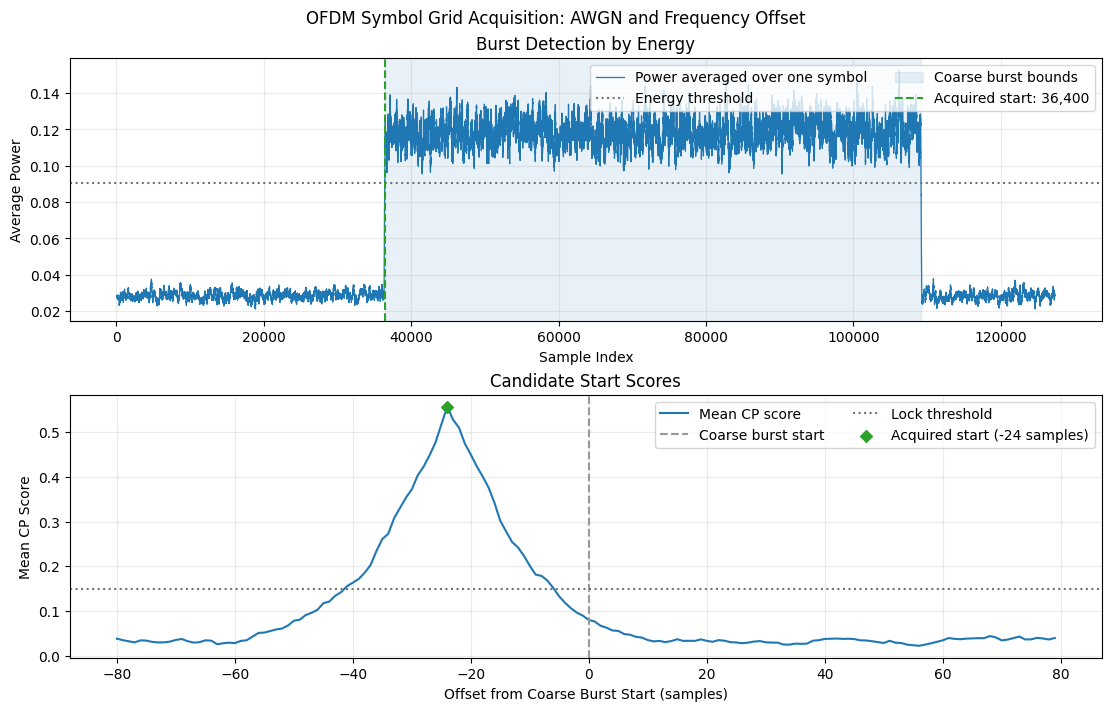

In [53]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), layout="constrained")
fig.suptitle(f"OFDM Symbol Grid Acquisition: {channel_titles[acquisition_case]}")

energy_ax, score_ax = axes
energy_ax.plot(energy_sample_indices, window_power, color="tab:blue", linewidth=0.9,
               label="Power averaged over one symbol")
if energy_threshold is not None:
    energy_ax.axhline(energy_threshold, color="0.45", linestyle=":", label="Energy threshold")
if burst_bounds is not None:
    energy_ax.axvspan(*burst_bounds, color="tab:blue", alpha=0.10, label="Coarse burst bounds")
if first_acquired_start is not None:
    energy_ax.axvline(first_acquired_start, color="tab:green", linestyle="--",
                      label=f"Acquired start: {first_acquired_start:,}")
energy_ax.set(title="Burst Detection by Energy", xlabel="Sample Index",
              ylabel="Average Power")
energy_ax.legend(loc="upper right", ncols=2)

if candidate_offsets.size:
    score_ax.plot(candidate_offsets, candidate_scores, color="tab:blue", label="Mean CP score")
    score_ax.axvline(0, color="0.6", linestyle="--", label="Coarse burst start")
else:
    score_ax.text(0.02, 0.95, "No timing candidates", transform=score_ax.transAxes, va="top")
score_ax.axhline(CP_LOCK_THRESHOLD, color="0.45", linestyle=":", label="Lock threshold")
if selected_offset is not None:
    score_ax.scatter(selected_offset, selected_score, color="tab:green", marker="D", zorder=4,
                     label=f"Acquired start ({selected_offset:+d} samples)")
score_ax.set(title="Candidate Start Scores",
             xlabel="Offset from Coarse Burst Start (samples)", ylabel="Mean CP Score")
score_ax.legend(loc="upper right", ncols=2)

for ax in axes:
    ax.grid(alpha=0.25)
plt.show()

In [54]:
# Compare local CP peaks, the acquired grid, and transmitted timing.
timing_metric = cp_metrics["awgn_cfo"]
timing_peaks = local_cp_peaks["awgn_cfo"]
timing_slots = (timing_peaks - leading_padding_samples + symbol_samples // 2) // symbol_samples
timing_starts = leading_padding_samples + timing_slots * symbol_samples
timing_offsets = timing_peaks - timing_starts
valid_timing = np.flatnonzero(
    (timing_slots >= 0) & (timing_slots < num_symbols) & (np.abs(timing_offsets) <= cp_len)
)

if valid_timing.size:
    example = valid_timing[np.argmax(np.abs(timing_offsets[valid_timing]))]
    true_start = timing_starts[example]
    detected_start = timing_peaks[example]
    detected_offset = timing_offsets[example]
    detected_metric = timing_metric[detected_start]
else:
    true_start = leading_padding_samples + (num_symbols // 2) * symbol_samples
    detected_start = None

zoom_samples = np.arange(max(0, true_start - cp_len), min(len(timing_metric), true_start + cp_len + 1))
zoom_metric = timing_metric[zoom_samples]
acquired_grid = detected_starts["awgn_cfo"]
grid_starts_in_view = acquired_grid[(acquired_grid >= zoom_samples[0]) & (acquired_grid <= zoom_samples[-1])]
acquired_start = grid_starts_in_view[0] if grid_starts_in_view.size else None

zoom_offsets = zoom_samples - true_start
acquired_offset = None
acquired_metric = None
if acquired_start is not None:
    acquired_offset = acquired_start - true_start
    acquired_metric = timing_metric[acquired_start]

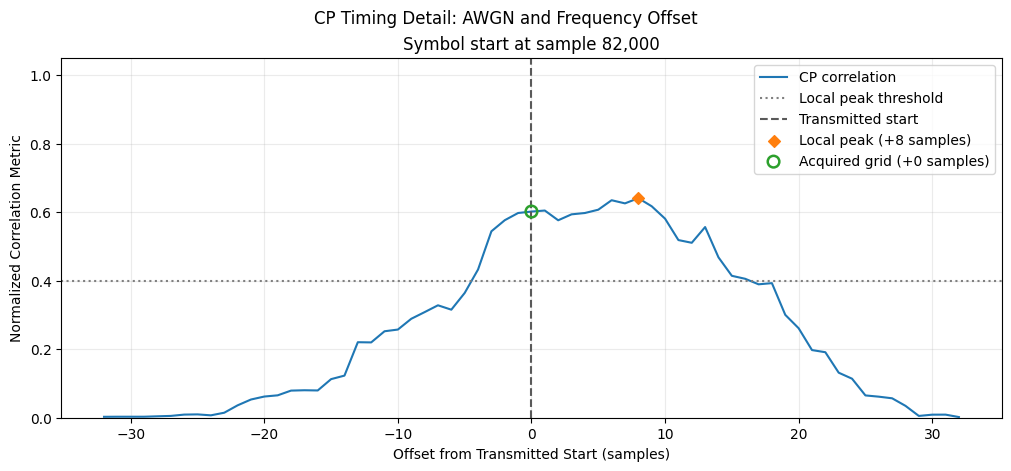

In [55]:
fig, ax = plt.subplots(figsize=(10, 4.6), layout="constrained")
fig.suptitle("CP Timing Detail: AWGN and Frequency Offset")
ax.plot(zoom_offsets, zoom_metric, label="CP correlation", color="tab:blue")
ax.axhline(CP_PEAK_THRESHOLD, color="0.5", linestyle=":", label="Local peak threshold")
ax.axvline(0, color="0.35", linestyle="--", label="Transmitted start")

if detected_start is not None:
    ax.scatter(detected_offset, detected_metric, color="tab:orange", marker="D", zorder=4,
               label=f"Local peak ({detected_offset:+d} samples)")
if acquired_offset is not None:
    if acquired_offset != 0:
        ax.axvline(acquired_offset, color="tab:green", linestyle="-.", alpha=0.7)
    ax.scatter(acquired_offset, acquired_metric, color="tab:green", s=70, facecolors="none",
               linewidths=1.8, zorder=5, label=f"Acquired grid ({acquired_offset:+d} samples)")
else:
    ax.text(0.02, 0.95, "No acquired grid in this window", transform=ax.transAxes, va="top")

ax.set(title=f"Symbol start at sample {true_start:,}",
       xlabel="Offset from Transmitted Start (samples)",
       ylabel="Normalized Correlation Metric", ylim=(0, 1.05))
ax.grid(alpha=0.25)
ax.legend(loc="upper right")
plt.show()

### Extract OFDM Symbols

In [56]:
symbol_offsets = np.arange(symbol_samples)
rx_symbol_blocks = {}
for case, signal in channel_signals.items():
    starts = detected_starts[case]
    sample_indices_by_symbol = starts[:, None] + symbol_offsets
    rx_symbol_blocks[case] = signal[sample_indices_by_symbol]

### Estimate and Compensate CFO

In [57]:
cfo_corrections_cycles_per_sample = {}
cfo_corrected_blocks = {}

for case, blocks in rx_symbol_blocks.items():
    prefix = blocks[:, :cp_len]
    tail = blocks[:, -cp_len:]
    cp_correlation = np.sum(prefix * np.conj(tail), axis=1)
    cp_phase = np.angle(cp_correlation)
    correction = cp_phase / (2 * np.pi * FFT_LEN)
    cfo_corrections_cycles_per_sample[case] = correction

    phase_ramp = np.exp(1j * 2 * np.pi * correction[:, None] * symbol_offsets)
    corrected_blocks = blocks.copy()
    corrected_blocks *= phase_ramp
    cfo_corrected_blocks[case] = corrected_blocks

In [58]:
# The measured offset has the opposite sign to the applied correction.
cfo_estimates_hz = {}
detected_symbol_numbers = {}
for case, correction in cfo_corrections_cycles_per_sample.items():
    cfo_estimates_hz[case] = -correction * sample_rate
    detected_symbol_numbers[case] = np.arange(1, correction.size + 1)

cfo_references_hz = {"ideal": 0, "awgn": 0, "cfo": channel_cfo_hz, "awgn_cfo": channel_cfo_hz}

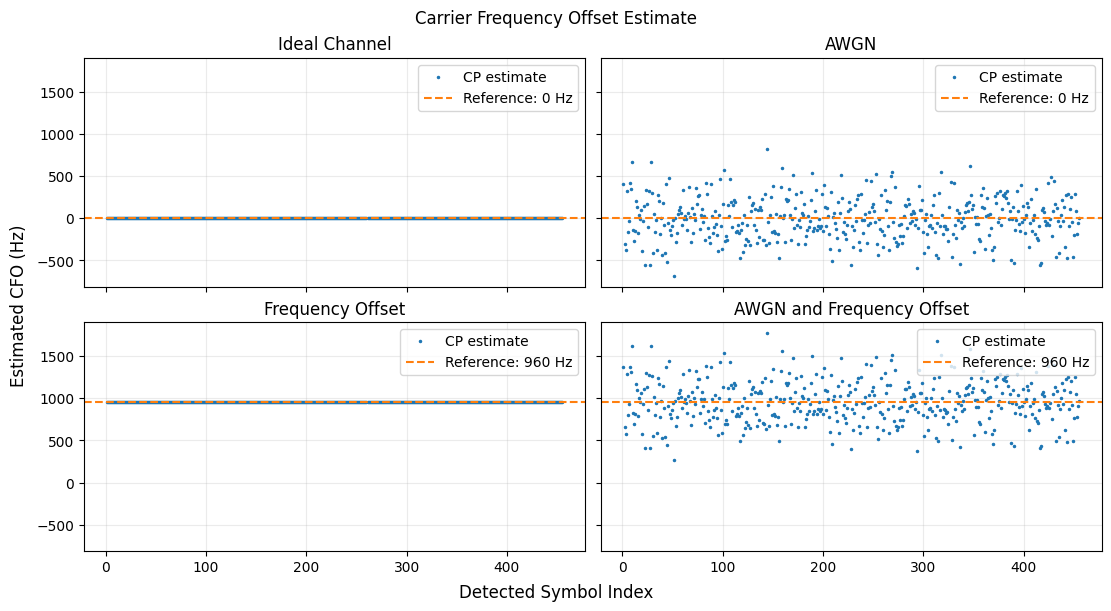

In [59]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Carrier Frequency Offset Estimate")
for ax, (case, title) in zip(axes.flat, channel_titles.items()):
    reference = cfo_references_hz[case]
    ax.plot(detected_symbol_numbers[case], cfo_estimates_hz[case], ".",
            markersize=3, color="tab:blue", label="CP estimate")
    ax.axhline(reference, color="tab:orange", linestyle="--", label=f"Reference: {reference:g} Hz")
    ax.set_title(title)
    ax.grid(alpha=0.25)
    ax.legend(loc="upper right")
fig.supxlabel("Detected Symbol Index")
fig.supylabel("Estimated CFO (Hz)")
plt.show()

### Remove the Prefix and Apply the FFT

In [60]:
def fft_symbols(blocks):
    spectrum = np.fft.fft(blocks, axis=1)
    return np.fft.fftshift(spectrum, axes=1) / np.sqrt(FFT_LEN)


useful_blocks = {}
frequency_blocks = {}
for case, blocks in cfo_corrected_blocks.items():
    samples_without_cp = blocks[:, cp_len:]
    useful_blocks[case] = samples_without_cp
    frequency_blocks[case] = fft_symbols(samples_without_cp)

### Estimate and Correct Pilot Phase

In [61]:
pilot_phase_offsets = {}
phase_corrected_blocks = {}

for case, spectrum in frequency_blocks.items():
    received_pilots = spectrum[:, pilot_mask]
    pilot_ratios = received_pilots / PILOT_VALUE
    common_phase = np.angle(np.mean(pilot_ratios, axis=1))
    pilot_phase_offsets[case] = common_phase

    corrected_blocks = useful_blocks[case].copy()
    corrected_blocks *= np.exp(-1j * common_phase[:, None])
    phase_corrected_blocks[case] = corrected_blocks

### Extract Data Subcarriers

In [62]:
received_data_points = {}
received_constellations = {}
for case, blocks in phase_corrected_blocks.items():
    corrected_spectrum = fft_symbols(blocks)
    received_data_points[case] = corrected_spectrum[:, data_mask]
    received_constellations[case] = received_data_points[case].ravel()

In [63]:
# Compare the same detected symbols with and without pilot phase correction.
constellation_before_pilots = frequency_blocks["awgn_cfo"][:, data_mask].ravel()
constellation_after_pilots = received_constellations["awgn_cfo"]

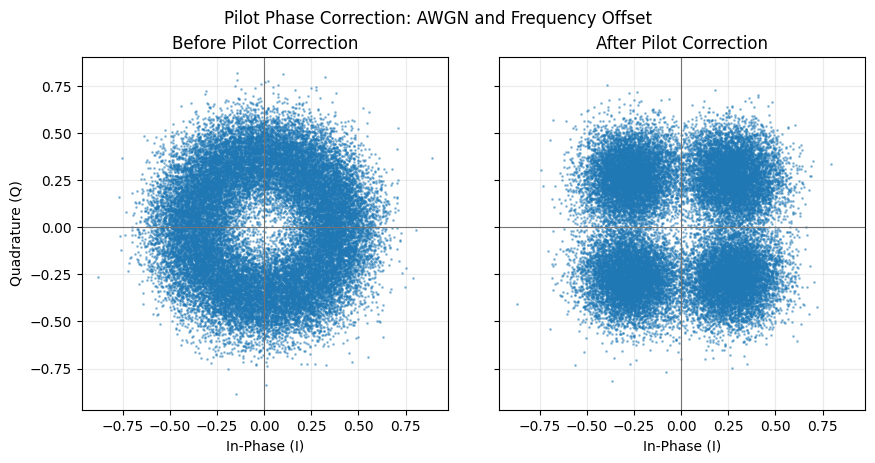

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4.5), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Pilot Phase Correction: AWGN and Frequency Offset")
for ax, constellation, title in zip(
    axes,
    (constellation_before_pilots, constellation_after_pilots),
    ("Before Pilot Correction", "After Pilot Correction"),
):
    ax.plot(constellation.real, constellation.imag, ".", markersize=2, alpha=0.4)
    ax.axhline(0, color="0.45", linewidth=0.8)
    ax.axvline(0, color="0.45", linewidth=0.8)
    ax.set(title=title, xlabel="In-Phase (I)", ylabel="Quadrature (Q)")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(alpha=0.25)
axes[1].label_outer()
plt.show()

## Results

Compare the received constellations across all four channel cases. Match each detection to the nearest transmitted symbol start within 32 samples. If multiple detections match the same symbol, keep the closest.

BER is the fraction of incorrect bits in matched symbols. Missed symbols and extra detections are counted separately. BER is undefined when there are no matches.

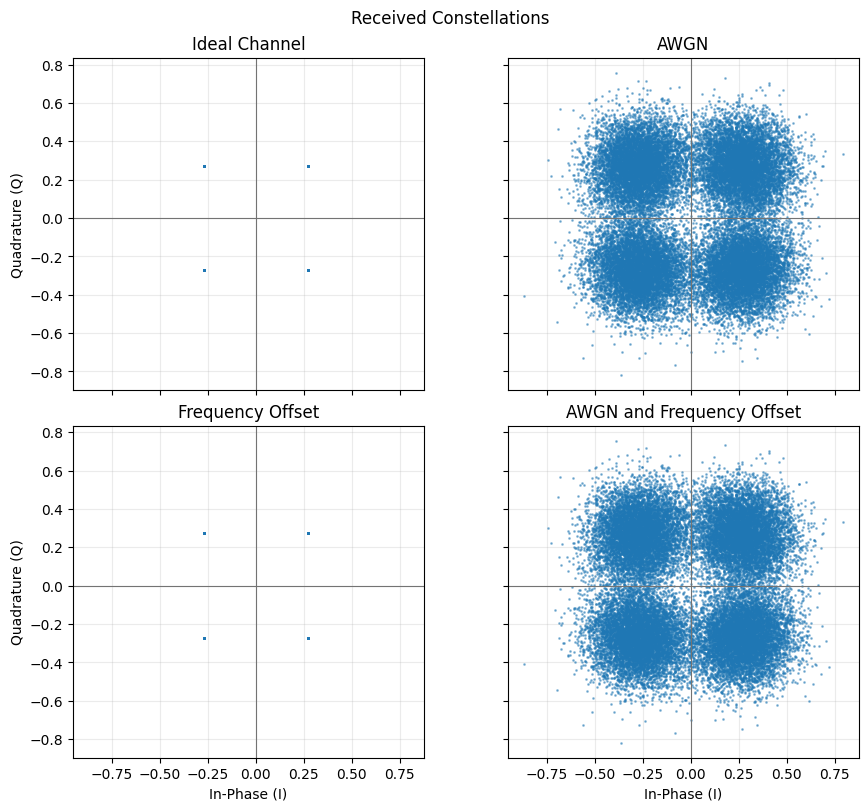

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8), sharex=True, sharey=True,
                         layout="constrained")
fig.suptitle("Received Constellations")
for ax, (case, title) in zip(axes.flat, channel_titles.items()):
    constellation = received_constellations[case]
    ax.plot(constellation.real, constellation.imag, ".", markersize=2, alpha=0.45)
    ax.axhline(0, color="0.45", linewidth=0.8)
    ax.axvline(0, color="0.45", linewidth=0.8)
    ax.set(title=title, xlabel="In-Phase (I)", ylabel="Quadrature (Q)")
    ax.set_aspect("equal", adjustable="box")
    ax.label_outer()
    ax.grid(alpha=0.25)
plt.show()

### Demodulation and BER Functions

In [66]:
def qpsk_demodulate(received_points):
    # The signs of I and Q recover the two bits of each constellation point.
    i_bits = (np.real(received_points) > 0).astype(int)
    q_bits = (np.imag(received_points) > 0).astype(int)
    demodulated_bits = np.empty(2 * len(received_points), dtype=int)
    demodulated_bits[::2] = i_bits
    demodulated_bits[1::2] = q_bits
    return demodulated_bits


def match_detected_symbols(detected_peaks):
    # The transmitted timing grid is available for evaluation in the simulation.
    offsets = np.asarray(detected_peaks, dtype=int) - leading_padding_samples
    transmitted_indices = (offsets + symbol_samples // 2) // symbol_samples
    timing_errors = np.abs(offsets - transmitted_indices * symbol_samples)

    matches = {}
    # Keep the closest detection when multiple peaks match one transmitted symbol.
    for received_index in np.argsort(timing_errors, kind="stable"):
        transmitted_index = transmitted_indices[received_index]
        inside_packet = 0 <= transmitted_index < num_symbols
        within_tolerance = timing_errors[received_index] <= cp_len
        if inside_packet and within_tolerance:
            matches.setdefault(transmitted_index, received_index)
    return matches


def measure_ber(received_points, detected_peaks):
    matches = match_detected_symbols(detected_peaks)
    bits_per_ofdm_symbol = len(data_mask) * BITS_PER_SYMBOL
    transmitted_bit_count = num_symbols * bits_per_ofdm_symbol
    transmitted_bit_blocks = transmit_bits[:transmitted_bit_count].reshape(
        num_symbols, bits_per_ofdm_symbol
    )

    bit_errors = 0
    for transmitted_index, received_index in matches.items():
        expected_bits = transmitted_bit_blocks[transmitted_index]
        received_bits = qpsk_demodulate(received_points[received_index])
        bit_errors += np.count_nonzero(received_bits != expected_bits)

    matched_symbols = len(matches)
    compared_bits = matched_symbols * bits_per_ofdm_symbol
    missed_symbols = num_symbols - matched_symbols
    extra_peaks = len(detected_peaks) - matched_symbols
    return bit_errors, compared_bits, missed_symbols, extra_peaks

### Calculate BER for Each Channel Case

In [67]:
ber_results = []
for case in channel_signals:
    errors, total, missed, extra = measure_ber(received_data_points[case], detected_starts[case])
    ber = errors / total if total else None
    ber_results.append((case, ber, errors, total, missed, extra))

In [68]:
ber_table = [
    "| Channel | BER | Bit Errors | Compared Bits | Missed Symbols | Extra Detections |",
    "| --- | ---: | ---: | ---: | ---: | ---: |",
]
for case, ber, errors, total, missed, extra in ber_results:
    formatted_ber = f"{ber:.3e}" if ber is not None else "N/A"
    ber_table.append(
        f"| {channel_titles[case]} | {formatted_ber} | {errors:,} | {total:,} | {missed:,} | {extra:,} |"
    )
display(Markdown("\n".join(ber_table)))

| Channel | BER | Bit Errors | Compared Bits | Missed Symbols | Extra Detections |
| --- | ---: | ---: | ---: | ---: | ---: |
| Ideal Channel | 0.000e+00 | 0 | 65,520 | 0 | 0 |
| AWGN | 1.470e-02 | 963 | 65,520 | 0 | 0 |
| Frequency Offset | 0.000e+00 | 0 | 65,520 | 0 | 0 |
| AWGN and Frequency Offset | 1.470e-02 | 963 | 65,520 | 0 | 0 |